## Linear Regression using Gradient Descent

In [168]:
import numpy as np

class LinearRegressionGD:
    def __init__(self, lr=0.01, epoch=1000):
        self.lr = lr
        self.epoch = epoch
        self.coeff_= None
        self.intercept_ = None
        

    def fit(self,x,y):
        self.coeff_ = np.ones(x.shape[1])
        self.intercept_ = 0
        self.loss_history_ = []

        for i in range(self.epoch):
            y_hat = np.dot(x, self.coeff_) + self.intercept_
            self.loss_history_.append(np.mean((y-y_hat)**2))
            intercept_der = -2 * np.mean(y-y_hat)
            self.intercept_ = self.intercept_ - (self.lr * intercept_der)

            coeff_der = -2 * np.dot((y-y_hat),x)/x.shape[0]

            self.coeff_ = self.coeff_ - (self.lr * coeff_der)
            
             
    def predict(self,x):
        return self.intercept_ + np.dot(x, self.coeff_)
        
    

### Making a model

In [10]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [223]:
x, y = load_diabetes(return_X_y=True,scaled=True)

In [224]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=11)

In [13]:
x.shape

(442, 10)

In [14]:
y.shape

(442,)

In [252]:
model = LinearRegressionGD(lr=0.1, epoch=10000)

In [253]:
model.fit(x_train,y_train)

In [254]:
pred = model.predict(x_test)

In [255]:
print("R2 score: ", r2_score(y_test, pred))

R2 score:  0.5713889413723263


In [256]:
x.std(axis=0)   


array([0.04756515, 0.04756515, 0.04756515, 0.04756515, 0.04756515,
       0.04756515, 0.04756515, 0.04756515, 0.04756515, 0.04756515])

In [257]:
model.loss_history_

[np.float64(28486.27333824245),
 np.float64(20202.2957328164),
 np.float64(14898.358785055952),
 np.float64(11501.646212570813),
 np.float64(9325.55863288404),
 np.float64(7930.674377210739),
 np.float64(7035.764808120886),
 np.float64(6460.844376822702),
 np.float64(6090.72282236986),
 np.float64(5851.678683182882),
 np.float64(5696.530411000816),
 np.float64(5595.081926419948),
 np.float64(5528.007801708503),
 np.float64(5482.939795260629),
 np.float64(5451.962244816422),
 np.float64(5430.009126271096),
 np.float64(5413.838175887634),
 np.float64(5401.37433144066),
 np.float64(5391.2895364221595),
 np.float64(5382.733815932165),
 np.float64(5375.163166016068),
 np.float64(5368.22940333144),
 np.float64(5361.709669248896),
 np.float64(5355.461312677564),
 np.float64(5349.393015201879),
 np.float64(5343.446311251245),
 np.float64(5337.583761061085),
 np.float64(5331.781381401381),
 np.float64(5326.023801264254),
 np.float64(5320.301161517567),
 np.float64(5314.607130691792),
 np.float6

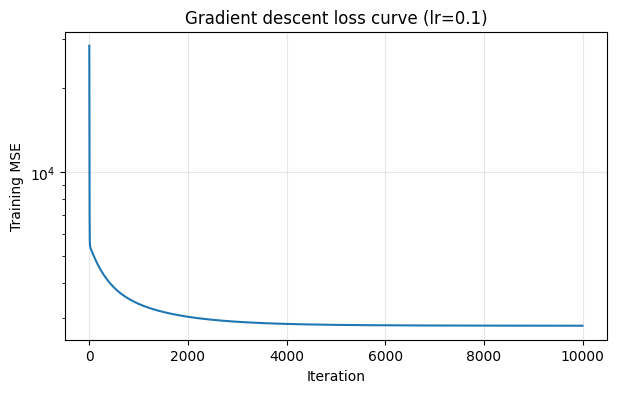

In [269]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(model.loss_history_)
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.title(f"Gradient descent loss curve (lr={model.lr})")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.savefig("loss_curve.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()